# RBF SVM parameter search

Compare native Moxie and scikit-learn on the Iris dataset. This follows the
[reference gallery example](https://scikit-learn.org/dev/auto_examples/svm/plot_rbf_parameters.html)
at revision `4358542a1bd39af2e7e1cbace8b9fed067473c5b`, using a smaller
logarithmic grid to focus on the cross-validation heatmap.

The gallery search scales the full dataset before evaluating the grid. The
second search puts scaling in the pipeline so each fold fits its own scaler.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
from moxie_nb import Session

nb = Session("svm/plot_rbf_parameters")
X, y = load_iris(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)
cs = np.logspace(-2, 2, 5)
gammas = np.logspace(-3, 1, 5)
folds = list(StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42).split(X, y))

reference = GridSearchCV(SVC(), {"C": cs, "gamma": gammas}, cv=folds).fit(X_scaled, y)
pipeline = make_pipeline(StandardScaler(), SVC(C=2.0, gamma=0.2))
reference_cv = cross_val_score(pipeline, X, y)
reference_pipeline = GridSearchCV(
    pipeline, {"svc__C": cs, "svc__gamma": gammas},
).fit(X, y)

nb.share(X=X, X_scaled=X_scaled, y=y.astype(np.float64), cs=cs, gammas=gammas,
         train=np.stack([train for train, _ in folds]),
         test=np.stack([test for _, test in folds]))

## Native Moxie

The [typed adapter](../../families/svm/examples/model_selection_adapter.mojo)
uses `EstimatorScore` for accuracy and maps numeric candidates to the SVC
parameter record. It uses the same Float64 feature matrices and converts Iris
targets to SVC's native `List[Float64]`. The gallery folds are materialized as
`List[IndexSplit]`. The pipeline uses the adapter's five-fold stratified
default.

In [2]:
adapter = (ROOT / "families/svm/examples/model_selection_adapter.mojo").read_text()
nb.run_mojo("search", adapter + """
from moxie.model_selection import GridSearchCV, cross_val_score
from moxie.pipeline import make_pipeline
from moxie_nb_io import load, save, save_floats, save_ints


def load_folds() raises -> List[IndexSplit]:
    var train = load[DType.int64]("train")
    var test = load[DType.int64]("test")
    var splits = List[IndexSplit]()
    for i in range(train.shape[0]):
        var fold_train = IndexArray(nm.Shape(train.shape[1]))
        var fold_test = IndexArray(nm.Shape(test.shape[1]))
        for j in range(fold_train.size):
            fold_train[nm.Item(j)] = train[nm.Item(i, j)]
        for j in range(fold_test.size):
            fold_test[nm.Item(j)] = test[nm.Item(i, j)]
        splits.append(IndexSplit(fold_train^, fold_test^))
    return splits^


def values(name: String) raises -> Labels:
    var input = load(name)
    var result = Labels(capacity=input.size)
    for i in range(input.size):
        result.append(input.item(i))
    return result^


def run_search[scaled: Bool](
    var model: SVCSearch[scaled].Estimator, X: Dense, y: Labels, prefix: String,
    var folds: Optional[List[IndexSplit]] = None,
) raises -> GridSearchCV[SVCSearch[scaled]]:
    comptime Adapter = SVCSearch[scaled]
    var grid = Dict[String, List[Float64]]()
    grid[prefix + "C"] = values("cs")
    grid[prefix + "gamma"] = values("gammas")
    var search = GridSearchCV[Adapter](model^, grid, Adapter(), cv=folds^)
    _ = search.fit(X, y)
    var result = search.cv_results_()
    var candidates = Dense(nm.Shape(len(result.params), 2))
    for i in range(len(result.params)):
        candidates[nm.Item(i, 0)] = result.params[i][prefix + "C"]
        candidates[nm.Item(i, 1)] = result.params[i][prefix + "gamma"]

    var tag = "pipeline" if scaled else "svc"
    save(tag + "_candidates", candidates)
    save(tag + "_folds", result.scores.test_scores)
    save(tag + "_mean", result.mean_test_score)
    save(tag + "_std", result.std_test_score)
    save(tag + "_rank", result.rank_test_score)
    save_ints(tag + "_best_index", [search.best_index_()])
    var best = search.best_params_()
    save_floats(tag + "_best_params", [best[prefix + "C"], best[prefix + "gamma"]])
    save_floats(tag + "_best_score", [search.best_score_()])
    return search^


def main() raises:
    var X = load("X")
    var X_scaled = load("X_scaled")
    var y = values("y")
    var bare_search = run_search[False](SVC(), X_scaled, y, "", load_folds())
    save_floats("svc_prediction", bare_search.predict(X_scaled))

    var pipeline = make_pipeline(StandardScaler(), SVC(C=2.0, gamma=0.2))
    var adapter = SVCSearch[True]()
    save("pipeline_cv", cross_val_score[SVCSearch[True]](
        pipeline, X, y, adapter, adapter.default_scorer(), adapter.default_cv(X, y), None, None,
    ))
    var pipeline_search = run_search[True](pipeline^, X, y, "svc__")
    save_floats("pipeline_prediction", pipeline_search.predict(X))
""", timeout=120)

## Search results

Both heatmaps show mean validation accuracy on the materialized shuffle splits.
The parity checks also cover every candidate and fold, the fold-local scaling
pipeline, and the best estimator refitted on all training rows.

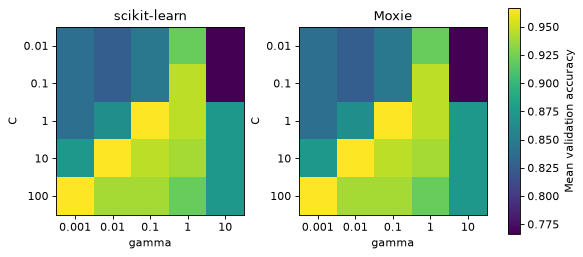

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
svc candidate order,PASS,"(25, 2)","(25, 2)",,,exact,0 mismatches,
svc fold scores,PASS,"(25, 5)","(25, 5)",,,exact,0 mismatches,
svc mean score,PASS,"(25,)","(25,)",0,0,"rtol=0, atol=2e-15",,Float64 reduction order over five identical fold scores
svc std score,PASS,"(25,)","(25,)",0,0,"rtol=0, atol=2e-15",,Float64 reduction order over five identical fold scores
svc ranks,PASS,"(25,)","(25,)",,,exact,0 mismatches,
svc best index,PASS,"(1,)","(1,)",,,exact,0 mismatches,
svc best parameters,PASS,"(2,)","(2,)",,,exact,0 mismatches,
svc best score,PASS,"(1,)","(1,)",0,0,"rtol=0, atol=2e-15",,Float64 reduction order over five identical fold scores
svc refit predictions,PASS,"(150,)","(150,)",,,exact,0 mismatches,
pipeline candidate order,PASS,"(25, 2)","(25, 2)",,,exact,0 mismatches,


In [3]:
native = nb.results["search"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), dpi=80, layout="constrained")
reference_means = reference.cv_results_["mean_test_score"]
for axis, label, means in zip(axes, ("scikit-learn", "Moxie"),
                             (reference_means, native["svc_mean"][:, 0])):
    image = axis.imshow(means.reshape(len(cs), len(gammas)),
                        vmin=reference_means.min(), vmax=reference_means.max())
    axis.set(xticks=np.arange(len(gammas)), xticklabels=[f"{g:g}" for g in gammas],
             yticks=np.arange(len(cs)), yticklabels=[f"{c:g}" for c in cs],
             xlabel="gamma", ylabel="C", title=label)
fig.colorbar(image, ax=axes, label="Mean validation accuracy")
plt.show()

for tag, search, prefix, data in (
    ("svc", reference, "", X_scaled),
    ("pipeline", reference_pipeline, "svc__", X),
):
    results = search.cv_results_
    keys = [prefix + "C", prefix + "gamma"]
    candidates = [[candidate[key] for key in keys] for candidate in results["params"]]
    scores = np.column_stack([results[f"split{i}_test_score"] for i in range(5)])
    nb.compare(f"{tag} candidate order", candidates, native[f"{tag}_candidates"], exact=True)
    nb.compare(f"{tag} fold scores", scores, native[f"{tag}_folds"][:, :, 0], exact=True)
    for stat in ("mean", "std"):
        nb.compare(f"{tag} {stat} score", results[f"{stat}_test_score"],
                   native[f"{tag}_{stat}"][:, 0], rtol=0, atol=2e-15,
                   reason="Float64 reduction order over five identical fold scores")
    nb.compare(f"{tag} ranks", results["rank_test_score"], native[f"{tag}_rank"][:, 0], exact=True)
    nb.compare(f"{tag} best index", [search.best_index_], native[f"{tag}_best_index"], exact=True)
    nb.compare(f"{tag} best parameters", [search.best_params_[key] for key in keys],
               native[f"{tag}_best_params"], exact=True)
    nb.compare(f"{tag} best score", [search.best_score_], native[f"{tag}_best_score"],
               rtol=0, atol=2e-15, reason="Float64 reduction order over five identical fold scores")
    nb.compare(f"{tag} refit predictions", search.predict(data), native[f"{tag}_prediction"], exact=True)

nb.compare("pipeline cross_val_score", reference_cv, native["pipeline_cv"], exact=True)
nb.report()
nb.assert_parity()